# FMCW Radar Sinyal İşleme ve Mikro-Doppler — Ders Defteri

Bu defter, `src/` klasöründeki beş scriptin tamamını sırayla çalıştırır. Google Colab'da açıp **Çalışma zamanı → Tümünü çalıştır** demen yeterli; kurulum gerekmez.

| Bölüm | Konu |
|---|---|
| 1 | Sinyal ve frekans |
| 2 | FFT temelleri |
| 3 | FMCW ile menzil ölçümü |
| 4 | Menzil-Doppler haritası |
| 5 | Mikro-Doppler: dron ve kuş |

## 1. Sinyal ve frekans

```
Sinüs dalgası, frekans ve genlik kavramları; iki sinüsün toplanmasıyla
oluşan karışık sinyal.

Signal & frequency: sine waves, frequency, amplitude and a mixed signal.
```

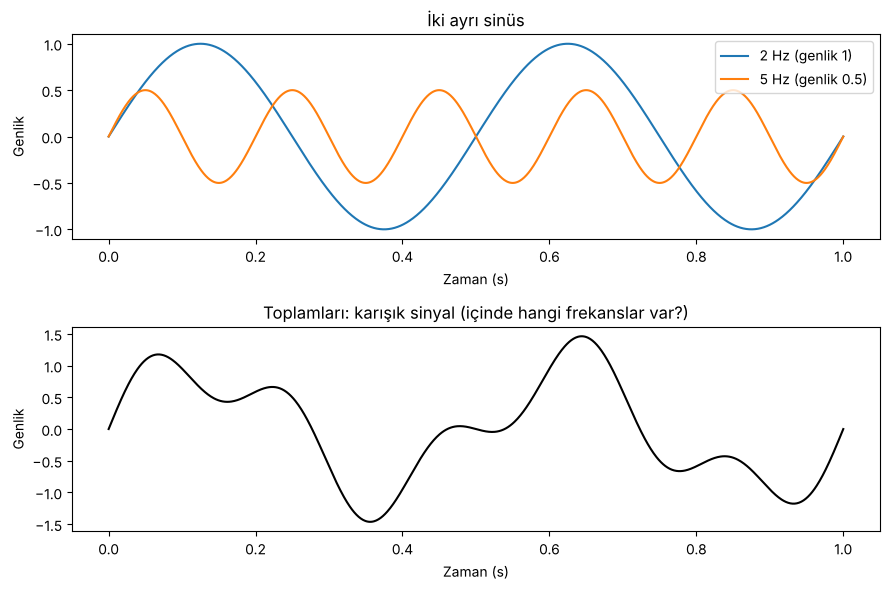

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

t = np.linspace(0, 1, 1000)            # 1 saniye, 1000 zaman noktası

yavas = np.sin(2 * np.pi * 2 * t)      # 2 Hz: saniyede 2 tam tur
hizli = 0.5 * np.sin(2 * np.pi * 5 * t)  # 5 Hz, genlik 0.5
karisik = yavas + hizli

fig, ax = plt.subplots(2, 1, figsize=(9, 6))
ax[0].plot(t, yavas, label="2 Hz (genlik 1)")
ax[0].plot(t, hizli, label="5 Hz (genlik 0.5)")
ax[0].set(title="İki ayrı sinüs", xlabel="Zaman (s)", ylabel="Genlik")
ax[0].legend()
ax[1].plot(t, karisik, color="k")
ax[1].set(title="Toplamları: karışık sinyal (içinde hangi frekanslar var?)",
          xlabel="Zaman (s)", ylabel="Genlik")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_sinyal_ve_frekans.png", dpi=150)
plt.show()

## 2. FFT temelleri

```
FFT (Fast Fourier Transform) karışık bir sinyalin içindeki frekansları ve
genliklerini bulur. Bu script üç şeyi gösterir:
  1. Gürültülü sinyalde bile FFT tepeleri doğru yerde çıkar (işleme kazancı).
  2. FFT'nin "benzerlik testi" mantığı: çarp ve ortala.
  3. Frekans çözünürlüğü: Δf = 1 / T

FFT basics: noise robustness, the multiply-and-average intuition and
frequency resolution (Δf = 1/T).
```

Benzerlik testi (çarp ve ortala):
  1 Hz -> 0.00
  2 Hz -> 1.00
  3 Hz -> 0.00
  4 Hz -> 0.00
  5 Hz -> 0.50
  6 Hz -> 0.00


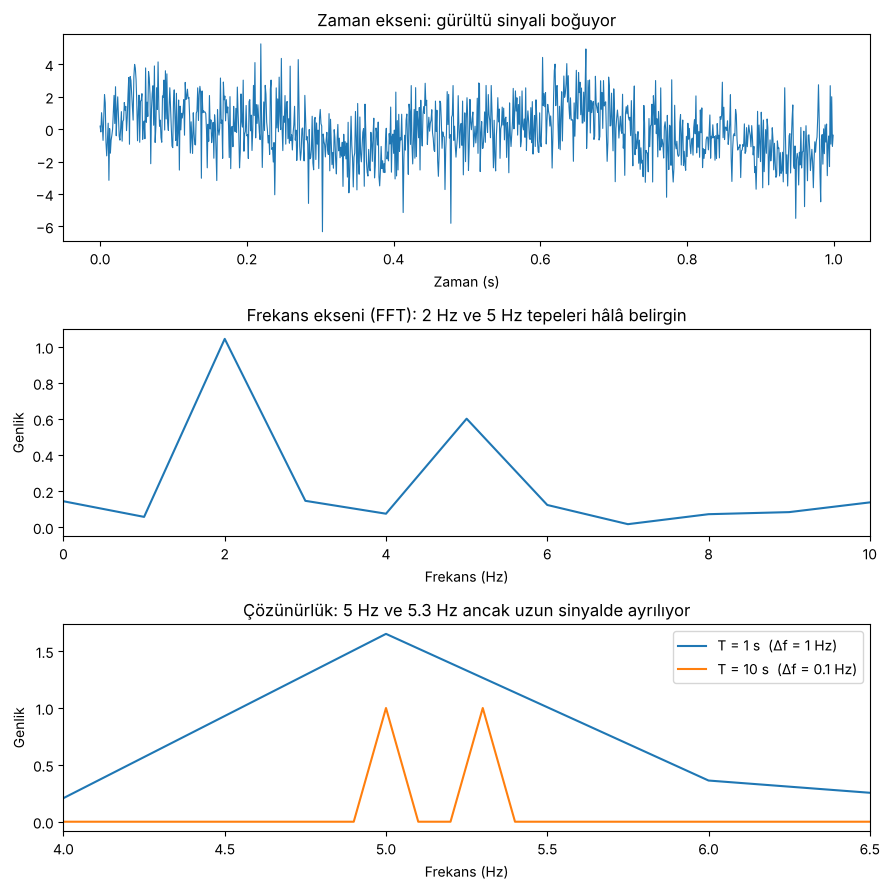

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

fs = 1000                                   # örnekleme frekansı [Hz]


def genlik_spektrumu(sinyal, fs):
    """Tek taraflı genlik spektrumu (tepe yüksekliği = sinüsün genliği)."""
    spektrum = np.fft.rfft(sinyal)
    frekanslar = np.fft.rfftfreq(len(sinyal), 1 / fs)
    return frekanslar, np.abs(spektrum) * 2 / len(sinyal)


# --- 1. Gürültülü sinyal ve FFT ---
t = np.arange(0, 1, 1 / fs)
temiz = 1.0 * np.sin(2 * np.pi * 2 * t) + 0.5 * np.sin(2 * np.pi * 5 * t)
gurultulu = temiz + 1.5 * rng.standard_normal(len(t))
f, A = genlik_spektrumu(gurultulu, fs)

# --- 2. Benzerlik testi: FFT'yi elle yapmak ---
print("Benzerlik testi (çarp ve ortala):")
for f_test in range(1, 7):
    benzerlik = np.mean(temiz * np.sin(2 * np.pi * f_test * t)) * 2
    print(f"  {f_test} Hz -> {benzerlik:.2f}")

# --- 3. Çözünürlük: 5 Hz ve 5.3 Hz ---
cozunurluk = []
for T in (1, 10):
    tt = np.arange(0, T, 1 / fs)
    s = np.sin(2 * np.pi * 5 * tt) + np.sin(2 * np.pi * 5.3 * tt)
    cozunurluk.append((T, *genlik_spektrumu(s, fs)))

fig, ax = plt.subplots(3, 1, figsize=(9, 9))
ax[0].plot(t, gurultulu, lw=0.8)
ax[0].set(title="Zaman ekseni: gürültü sinyali boğuyor", xlabel="Zaman (s)")
ax[1].plot(f, A)
ax[1].set(title="Frekans ekseni (FFT): 2 Hz ve 5 Hz tepeleri hâlâ belirgin",
          xlabel="Frekans (Hz)", ylabel="Genlik", xlim=(0, 10))
for T, ff, AA in cozunurluk:
    ax[2].plot(ff, AA, label=f"T = {T} s  (Δf = {1 / T:g} Hz)")
ax[2].set(title="Çözünürlük: 5 Hz ve 5.3 Hz ancak uzun sinyalde ayrılıyor",
          xlabel="Frekans (Hz)", ylabel="Genlik", xlim=(4, 6.5))
ax[2].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_fft_temelleri.png", dpi=150)
plt.show()

## 3. FMCW ile menzil ölçümü

```
FMCW (Frequency Modulated Continuous Wave) radar, frekansı doğrusal artan bir
sinyal (chirp) gönderir. Yankı, chirp'in gecikmiş kopyasıdır; ikisinin
karıştırılmasıyla elde edilen beat (fark) frekansı mesafeyle doğru orantılıdır:

    τ   = 2R / c          (yankı gecikmesi)
    f_b = S · τ = 2SR / c (S = B / Tc, chirp eğimi)
    R   = f_b · c / (2S)

Range FFT, beat frekansını bulur; eksen formülle metreye çevrilir.

FMCW range measurement: chirp, beat frequency and the range FFT.
```

Menzil çözünürlüğü ΔR = c/2B = 1.00 m
50 m -> beat frekansı 2.50 MHz
80 m -> beat frekansı 4.00 MHz


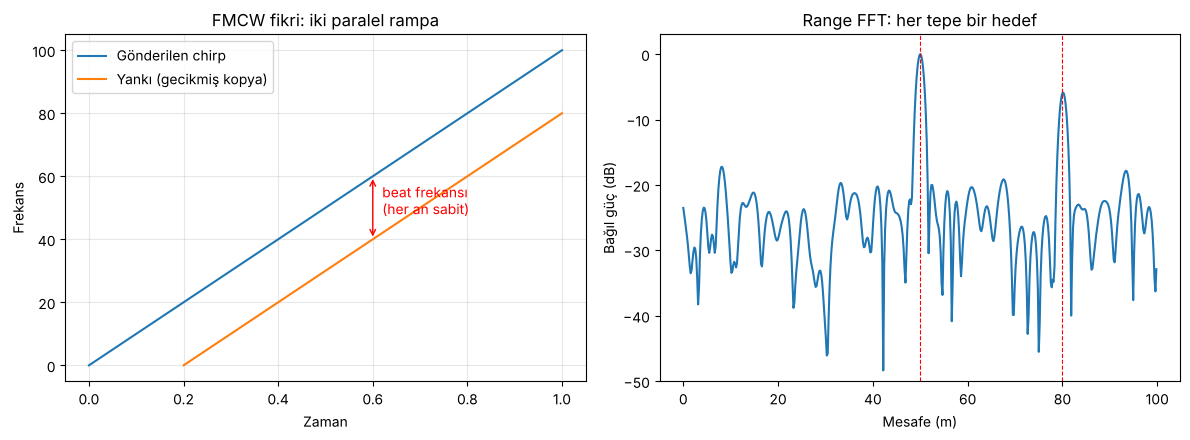

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

# --- Radar parametreleri ---
c = 3e8            # ışık hızı [m/s]
B = 150e6          # chirp bant genişliği [Hz]
Tc = 20e-6         # chirp süresi [s]
S = B / Tc         # chirp eğimi [Hz/s]
fs = 10e6          # ADC örnekleme frekansı [Hz]
t = np.arange(0, Tc, 1 / fs)

print(f"Menzil çözünürlüğü ΔR = c/2B = {c / (2 * B):.2f} m")

# --- Hedefler: (mesafe [m], genlik) ---
hedefler = [(50, 1.0), (80, 0.5)]

sinyal = np.zeros(len(t), dtype=complex)
for R, A in hedefler:
    f_b = 2 * S * R / c
    print(f"{R} m -> beat frekansı {f_b / 1e6:.2f} MHz")
    sinyal += A * np.exp(1j * 2 * np.pi * f_b * t)
sinyal += 0.5 * (rng.standard_normal(len(t)) + 1j * rng.standard_normal(len(t)))

# --- Range FFT (Hanning penceresi yan lobları bastırır) ---
N_fft = 1024
spektrum = np.abs(np.fft.fft(sinyal * np.hanning(len(t)), N_fft))
mesafeler = np.fft.fftfreq(N_fft, 1 / fs) * c / (2 * S)
pozitif = mesafeler >= 0

# --- Çizim ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Sol: chirp ve yankının zaman-frekans grafiği (oyuncak sayılarla)
tt = np.linspace(0, 1, 500)
gecikme = 0.2
ax[0].plot(tt, 100 * tt, label="Gönderilen chirp")
ax[0].plot(tt[tt >= gecikme], 100 * (tt[tt >= gecikme] - gecikme), label="Yankı (gecikmiş kopya)")
ax[0].annotate("", xy=(0.6, 60), xytext=(0.6, 40),
               arrowprops=dict(arrowstyle="<->", color="red"))
ax[0].text(0.62, 48, "beat frekansı\n(her an sabit)", color="red")
ax[0].set(title="FMCW fikri: iki paralel rampa", xlabel="Zaman", ylabel="Frekans")
ax[0].legend(loc="upper left")
ax[0].grid(alpha=0.3)

# Sağ: range FFT
dB = 20 * np.log10(spektrum[pozitif] + 1e-12)
ax[1].plot(mesafeler[pozitif], dB - dB.max())
for R, _ in hedefler:
    ax[1].axvline(R, color="r", ls="--", lw=0.8)
ax[1].set(title="Range FFT: her tepe bir hedef", xlabel="Mesafe (m)",
          ylabel="Bağıl güç (dB)", ylim=(-50, 3))
plt.tight_layout()
plt.savefig(FIG_DIR / "03_fmcw_menzil.png", dpi=150)
plt.show()

## 4. Menzil-Doppler haritası

```
Tek chirp Doppler kaymasını göremez (20 µs'lik chirp'te FFT çözünürlüğü 50 kHz).
Bunun yerine art arda çok chirp gönderilir; hareketli hedefin fazı her chirp'te
biraz döner. Veriler bir tabloya dizilir (satır = chirp, sütun = örnek):

  1. FFT satırlar boyunca (hızlı zaman)  -> mesafe
  2. FFT sütunlar boyunca (yavaş zaman)  -> hız

    f_D   = 2v / λ          (Doppler kayması)
    v_max = λ / (4 Tc)      (bunu aşan hız aliasing yapar)

Range-Doppler processing with a 2D FFT over fast time and slow time.
```

Maksimum ölçülebilir hız: ±48.7 m/s
Hız çözünürlüğü: 1.52 m/s


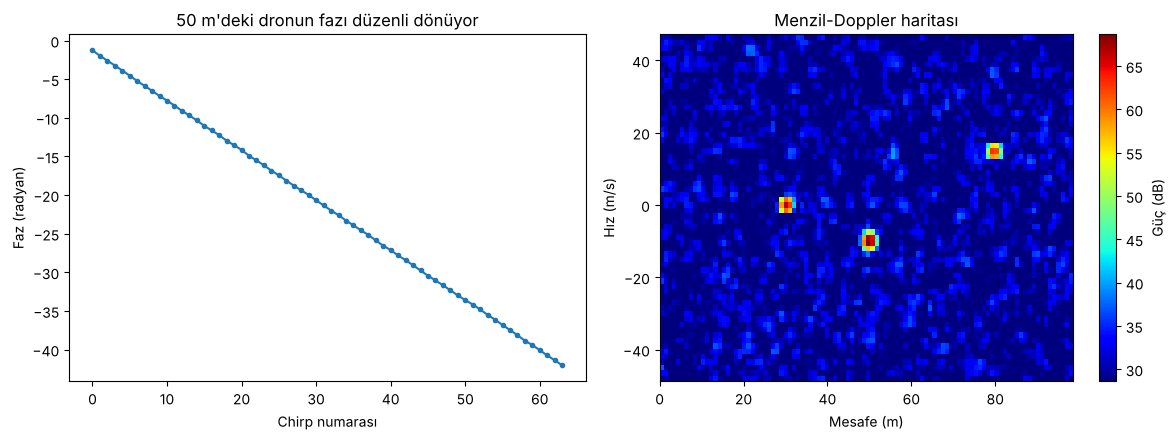

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

# --- Radar parametreleri ---
c = 3e8
fc = 77e9                      # taşıyıcı frekans [Hz]
lam = c / fc                   # dalga boyu ≈ 3.9 mm
B, Tc, fs = 150e6, 20e-6, 10e6
S = B / Tc
t = np.arange(0, Tc, 1 / fs)   # hızlı zaman (200 örnek)
n_chirp = 64                   # yavaş zaman

print(f"Maksimum ölçülebilir hız: ±{lam / (4 * Tc):.1f} m/s")
print(f"Hız çözünürlüğü: {lam / (2 * n_chirp * Tc):.2f} m/s")

# --- Hedefler: (mesafe [m], hız [m/s], genlik); hız < 0 = yaklaşıyor ---
hedefler = [(50, -10, 1.0),
            (80, 15, 0.5),
            (30, 0, 0.7)]       # duran nesne (ör. bina, ağaç)

veri = np.zeros((n_chirp, len(t)), dtype=complex)
for k in range(n_chirp):
    for R0, v, A in hedefler:
        R = R0 + v * k * Tc                    # hedef her chirp'te biraz ilerler
        f_b = 2 * S * R / c
        faz = 4 * np.pi * R / lam              # mesafeye çok hassas faz
        veri[k] += A * np.exp(1j * (2 * np.pi * f_b * t + faz))
veri += 0.5 * (rng.standard_normal(veri.shape) + 1j * rng.standard_normal(veri.shape))

# --- 2D FFT (her iki eksende Hanning penceresi) ---
pencere = np.outer(np.hanning(n_chirp), np.hanning(len(t)))
menzil_fft = np.fft.fft(veri * pencere, axis=1)
rdm = np.fft.fftshift(np.fft.fft(menzil_fft, axis=0), axes=0)
rdm_dB = 20 * np.log10(np.abs(rdm) + 1e-12)

mesafeler = np.fft.fftfreq(len(t), 1 / fs) * c / (2 * S)
hizlar = np.fft.fftshift(np.fft.fftfreq(n_chirp, Tc)) * lam / 2
yarim = len(t) // 2

# 50 m'deki hedefin fazı chirp'ten chirp'e (pencere olmadan)
kutu = np.argmin(np.abs(mesafeler - 50))
fazlar = np.unwrap(np.angle(np.fft.fft(veri, axis=1)[:, kutu]))

# --- Çizim ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fazlar, "o-", ms=3)
ax[0].set(title="50 m'deki dronun fazı düzenli dönüyor", xlabel="Chirp numarası",
          ylabel="Faz (radyan)")
im = ax[1].imshow(rdm_dB[:, :yarim], aspect="auto", origin="lower", cmap="jet",
                  extent=[0, mesafeler[yarim - 1], hizlar[0], hizlar[-1]],
                  vmin=rdm_dB.max() - 40)
fig.colorbar(im, ax=ax[1], label="Güç (dB)")
ax[1].set(title="Menzil-Doppler haritası", xlabel="Mesafe (m)", ylabel="Hız (m/s)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_menzil_doppler_haritasi.png", dpi=150)
plt.show()

## 5. Mikro-Doppler: dron ve kuş

```
Gövde tek bir hızla ilerler; dönen pervaneler ve çırpan kanatlar ise ek,
zamanla değişen hızlar üretir (mikro-Doppler). Bu deseni görmek için yavaş
zaman sinyaline STFT (Short-Time Fourier Transform) uygulanır ve spektrogram
çizilir. Hedefler, küçük yansıtıcı noktaların (scatterer) toplamı olarak
modellenir.

  Dron : düzenli dikey "blade flash"lar; aralık -> devir, yükseklik -> kanat ucu hızı
  Kuş  : gövde çizgisi etrafında yavaş sinüs dalgası

Not: Pervane ucu ≈ 60 m/s olduğundan 77 GHz'teki ±48.7 m/s sınırı aşılır.
Bu yüzden burada 24 GHz (λ = 12.5 mm) ve PRF = 50 kHz kullanılır (±156 m/s).

Micro-Doppler signatures of a drone and a bird via STFT spectrograms.
```

Maksimum ölçülebilir hız: ±156 m/s


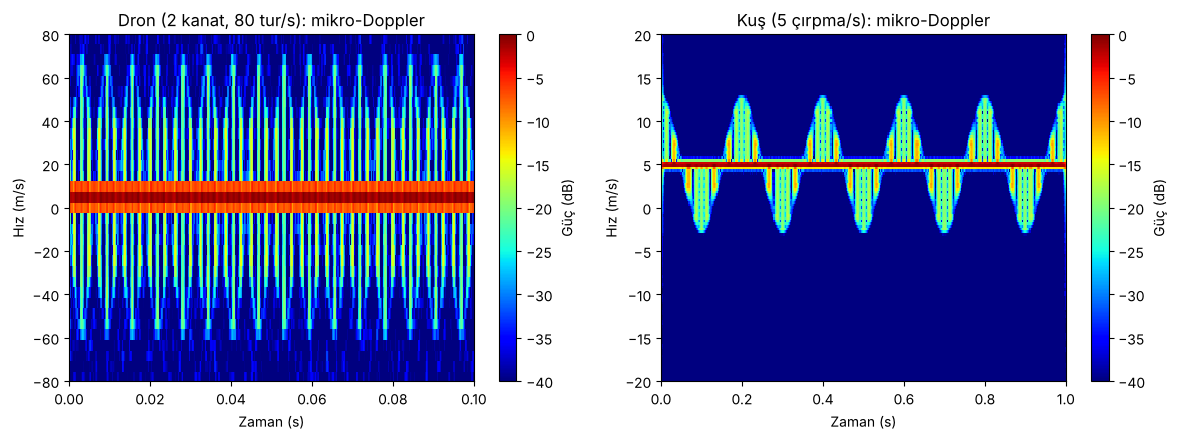

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import stft

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

# --- Radar parametreleri ---
c = 3e8
fc = 24e9                      # K bandı
lam = c / fc                   # 12.5 mm
PRF = 50_000                   # saniyedeki chirp sayısı
t = np.arange(0, 1.0, 1 / PRF) # yavaş zaman, 1 saniye

print(f"Maksimum ölçülebilir hız: ±{lam * PRF / 4:.0f} m/s")


def yanki(R, A):
    """Tek bir yansıtıcı noktanın yavaş zaman sinyali."""
    return A * np.exp(1j * 4 * np.pi * R / lam)


def dron_sinyali(R0=50, v=5, yaricap=0.12, devir=80, kanat_sayisi=2, n_nokta=15):
    s = yanki(R0 + v * t, 1.0)                                   # gövde
    for k in range(kanat_sayisi):
        aci = 2 * np.pi * devir * t + k * 2 * np.pi / kanat_sayisi
        for l in np.linspace(0.01, yaricap, n_nokta):          # kanat boyunca noktalar
            s += yanki(R0 + v * t + l * np.cos(aci), 0.05)
    return s


def kus_sinyali(R0=50, v=5, kanat_boyu=0.30, cirpma=5, genlik_aci=0.8, n_nokta=15):
    s = yanki(R0 + v * t, 1.0)                                   # gövde
    kanat_acisi = genlik_aci * np.sin(2 * np.pi * cirpma * t)   # yukarı-aşağı
    for l in np.linspace(0.02, kanat_boyu, n_nokta):
        s += 2 * yanki(R0 + v * t + l * np.sin(kanat_acisi), 0.05)  # 2 kanat
    return s


def spektrogram(sinyal, pencere):
    f, zaman, Z = stft(sinyal, fs=PRF, nperseg=pencere, noverlap=pencere * 7 // 8,
                       return_onesided=False)
    f, Z = np.fft.fftshift(f), np.fft.fftshift(Z, axes=0)
    dB = 20 * np.log10(np.abs(Z) + 1e-12)
    return zaman, f * lam / 2, dB - dB.max()


def gurultu_ekle(s, seviye=0.05):
    return s + seviye * (rng.standard_normal(len(s)) + 1j * rng.standard_normal(len(s)))


if __name__ == "__main__":
    # (ad, sinyal, pencere, gösterilen süre [s], hız sınırı [m/s])
    ayarlar = [("Dron (2 kanat, 80 tur/s)", gurultu_ekle(dron_sinyali()), 64, 0.1, 80),
               ("Kuş (5 çırpma/s)", gurultu_ekle(kus_sinyali()), 1024, 1.0, 20)]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for a, (ad, s, pencere, goster, vlim) in zip(ax, ayarlar):
        zaman, hiz, dB = spektrogram(s, pencere)
        im = a.pcolormesh(zaman, hiz, dB, vmin=-40, cmap="jet", shading="auto")
        a.set(title=f"{ad}: mikro-Doppler", xlabel="Zaman (s)", ylabel="Hız (m/s)",
              xlim=(0, goster), ylim=(-vlim, vlim))
        fig.colorbar(im, ax=a, label="Güç (dB)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "05_mikro_doppler.png", dpi=150)
    plt.show()